<a href="https://colab.research.google.com/github/lovnishverma/Python-Getting-Started/blob/main/Module_5_Computer_Vision.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Module 5: Computer Vision and its Applications
### A hands-on notebook for absolute beginners

**What you will learn**
1. What Computer Vision is
2. Image basics: how images are represented, pixels, color models
3. Image filtering: blurring, sharpening, edge detection (Sobel, Canny)
4. The OpenCV library in Python

**How to use this notebook**
- A notebook is made of **cells**. Text cells explain. Code cells run Python.
- To run a code cell, click it and press **Shift + Enter** (or click the Run button).
- Run the cells **in order, from top to bottom**. Or use **Runtime → Run all**.
- Lines starting with `#` are **comments**. They are notes for you, and Python ignores them.
- **Try it** boxes ask you to change a value and run the cell again. You cannot break anything!

> If you see `NameError: name '...' is not defined`, you probably skipped a cell. Use **Runtime → Run all**.

---
# Part 1: Introduction to Computer Vision

**Computer Vision (CV)** is a field of Artificial Intelligence that helps computers **get useful information from images and videos**.

You look at a photo and instantly say *"that is a cup of coffee."* A computer only sees **a big table of numbers**. Computer Vision is how we turn those numbers into meaning.

### A typical Computer Vision pipeline
**Capture** → **Pre-process** (resize, remove noise) → **Find features** (edges, shapes) → **Understand / Decide**

*This is a simple picture. Modern deep learning systems often learn the features automatically.*

### Common tasks
| Task | Question it answers | Example |
|---|---|---|
| Image classification | *What is in this image?* | "This is a cat" |
| Object detection | *What is where?* | Boxes around cars and people |
| Segmentation | *Which pixels belong to what?* | Separating the road from the sky |
| Face detection | *Is there a face, and where?* | Camera focus box |
| Face recognition | *Whose face is it?* | Phone unlock |
| OCR (Optical Character Recognition) | *What text is written?* | Scanning a document |

### Applications in real life
- **Healthcare:** helping doctors examine X-rays and scans
- **Transport:** driver assistance, reading number plates
- **Agriculture:** spotting crop diseases from leaf photos
- **Manufacturing:** finding defective products
- **Retail:** barcode scanning, automated checkout
- **Security:** video monitoring, identity checks
- **Daily life:** photo filters, portrait mode, document scanner apps

> **Use it responsibly:** CV systems can make mistakes and can be unfair if trained on unbalanced data. Using faces also raises privacy and consent concerns.

---
# Part 2: Setup

We use these **libraries** (ready-made Python toolboxes):

| Library | Short name | What it does |
|---|---|---|
| OpenCV | `cv2` | Image processing and computer vision |
| NumPy | `np` | Works with tables of numbers |
| Matplotlib | `plt` | Shows images and charts |
| scikit-image | `data` | Gives us free sample images |

Google Colab already has these installed.

In [1]:
import cv2                          # OpenCV
import numpy as np                  # numbers and arrays
import matplotlib.pyplot as plt     # display images
from skimage import data            # sample images

print("All libraries loaded!")
print("OpenCV version:", cv2.__version__)

All libraries loaded!
OpenCV version: 4.14.0


### A helper to show images
We will show many images, so we write one small **function** now and reuse it.
**You do not need to understand every line yet.** Just run it.

How to use it: `show([image1, image2], ["title 1", "title 2"])`

In [2]:
def show(images, titles):
    """Show one or more images side by side."""
    plt.figure(figsize=(5 * len(images), 5))
    for i, (img, title) in enumerate(zip(images, titles)):
        plt.subplot(1, len(images), i + 1)
        if img.ndim == 2:      # 2D means a grayscale image
            plt.imshow(img, cmap="gray", vmin=0, vmax=255)
        else:                  # 3D means a color (RGB) image
            plt.imshow(img)
        plt.title(title)
        plt.axis("off")
    plt.tight_layout()
    plt.show()

print("Helper function ready!")

Helper function ready!


---
# Part 3: Image Processing Basics

## 3.1 What is a pixel?
A digital image is a **grid of tiny squares** called **pixels** (short for *picture elements*). Each pixel stores numbers.

In a common **8-bit grayscale** image, each pixel is **one number from 0 to 255**:
- `0` = black
- `128` = gray
- `255` = white

Let's **create an image by typing numbers!**

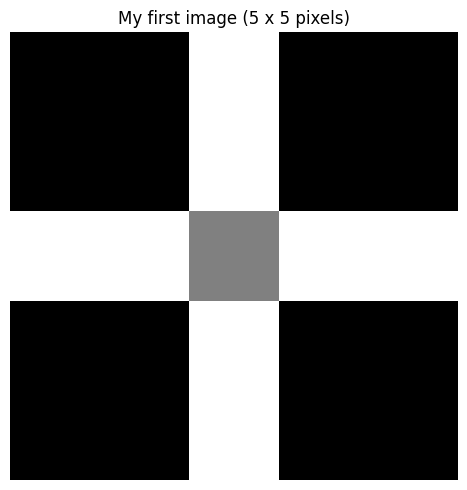

In [3]:
# A tiny 5 x 5 image, shaped like a plus sign
tiny = np.array([
    [  0,   0, 255,   0,   0],
    [  0,   0, 255,   0,   0],
    [255, 255, 128, 255, 255],
    [  0,   0, 255,   0,   0],
    [  0,   0, 255,   0,   0]
], dtype=np.uint8)   # uint8 = whole numbers from 0 to 255

show([tiny], ["My first image (5 x 5 pixels)"])

> **Try it:** Change some numbers above (for example, make the center `0`) and run the cell again.

## 3.2 How is an image represented?
For a computer, an image is a **NumPy array**:
- **Grayscale image** → 2D array: `(height, width)`
- **Color image** → 3D array: `(height, width, channels)`

Now let's load a real photo.

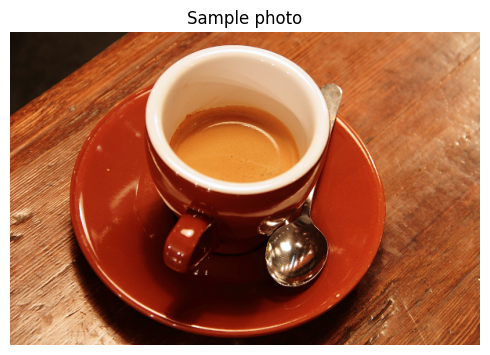

Shape (height, width, channels): (400, 600, 3)
Data type: uint8
Smallest value: 0 | Largest value: 255
Total pixels: 240000


In [4]:
photo = data.coffee()   # a sample color photo, in RGB order

show([photo], ["Sample photo"])

print("Shape (height, width, channels):", photo.shape)
print("Data type:", photo.dtype)
print("Smallest value:", photo.min(), "| Largest value:", photo.max())
print("Total pixels:", photo.shape[0] * photo.shape[1])

**Reading the shape:** `(400, 600, 3)` means 400 rows (height), 600 columns (width) and 3 color values per pixel.
The **resolution** is usually written as width × height: **600 × 400**.

## 3.3 Reading and changing pixels
We access a pixel with `image[row, column]`.
- Counting starts at **0**
- `(0, 0)` is the **top-left** corner
- **Row comes first** (how far down), then column (how far right)

In [5]:
pixel = photo[100, 200]     # row 100, column 200
print("Pixel at row 100, column 200:", pixel)
print("Red =", pixel[0], " Green =", pixel[1], " Blue =", pixel[2])

Pixel at row 100, column 200: [203 143  85]
Red = 203  Green = 143  Blue = 85


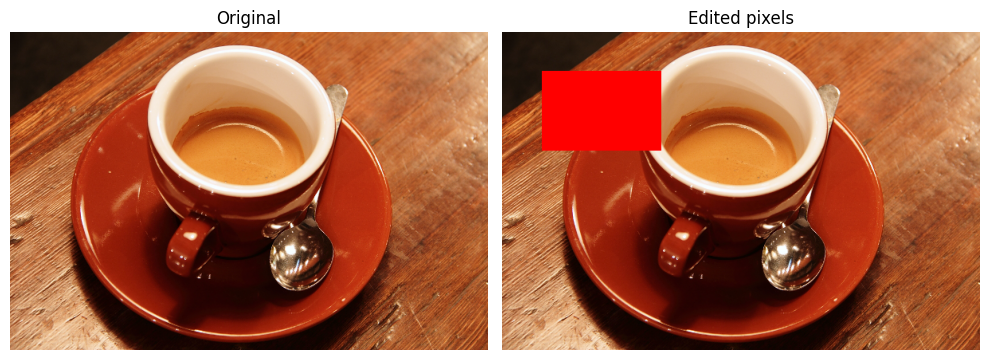

In [6]:
edited = photo.copy()   # always edit a copy, so the original stays safe

# [rows, columns]  ->  rows 50 to 149, columns 50 to 199
edited[50:150, 50:200] = [255, 0, 0]    # paint it red

show([photo, edited], ["Original", "Edited pixels"])

### Cropping
Cropping is just **selecting a part** of the array.

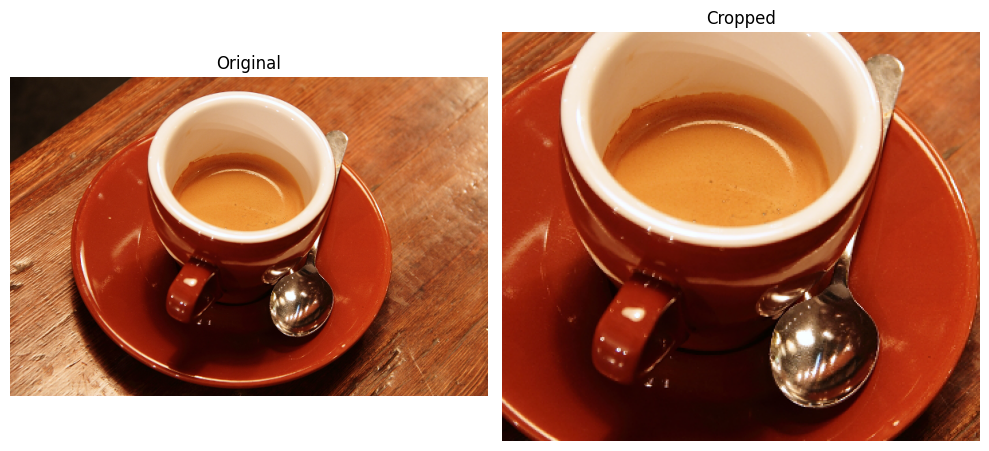

Cropped shape: (300, 350, 3)


In [7]:
crop = photo[50:350, 130:480]    # [top:bottom, left:right]

show([photo, crop], ["Original", "Cropped"])
print("Cropped shape:", crop.shape)

> **Try it:** Change the four crop numbers. Can you crop only the spoon?

## 3.4 Color models
A **color model** is a way of describing a color using numbers.

| Model | Channels | Commonly used for |
|---|---|---|
| **RGB** | Red, Green, Blue | Screens and cameras |
| **BGR** | Blue, Green, Red | OpenCV's default order (same colors as RGB, different order) |
| **Grayscale** | Brightness only | Simpler processing, edge detection |
| **HSV** | Hue, Saturation, Value | Picking out objects by color |
| **CMYK** | Cyan, Magenta, Yellow, Black | Printing |

### RGB: mixing light
Each channel goes from 0 to 255. For example, red + green light makes **yellow**.

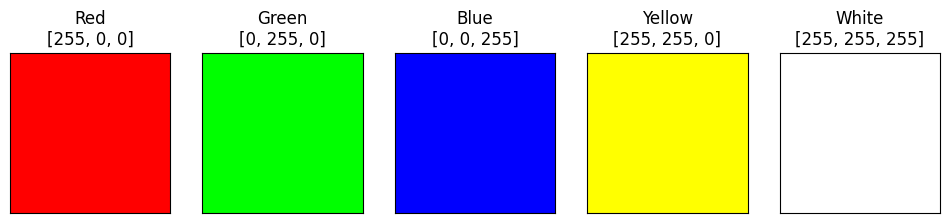

In [8]:
colors = {
    "Red": [255, 0, 0],       "Green": [0, 255, 0],   "Blue": [0, 0, 255],
    "Yellow": [255, 255, 0],  "White": [255, 255, 255]
}

# Make a 100 x 100 block of each color
blocks = [np.full((100, 100, 3), value, dtype=np.uint8) for value in colors.values()]
titles = [f"{name}\n{value}" for name, value in colors.items()]

plt.figure(figsize=(12, 3))
for i in range(len(blocks)):
    plt.subplot(1, 5, i + 1)
    plt.imshow(blocks[i])
    plt.title(titles[i])
    plt.xticks([]); plt.yticks([])
plt.show()

> **Try it:** Add `"My color": [255, 128, 0]` to the dictionary. Then change `plt.subplot(1, 5, i + 1)` to `plt.subplot(1, 6, i + 1)`.

### Splitting RGB channels
In each picture below, **brighter means more of that color** at that pixel.

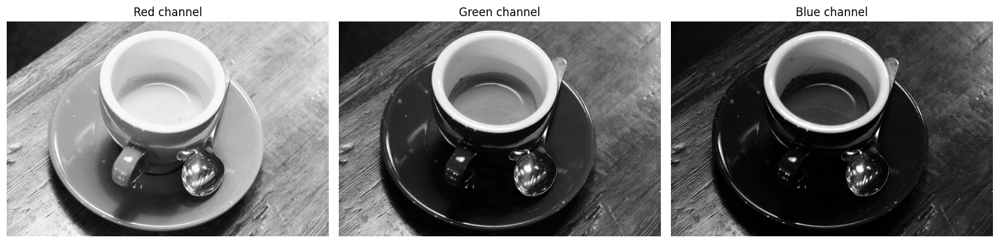

In [9]:
red   = photo[:, :, 0]    # ":" means "take everything"
green = photo[:, :, 1]
blue  = photo[:, :, 2]

show([red, green, blue], ["Red channel", "Green channel", "Blue channel"])

### Grayscale
Grayscale keeps only brightness: **1 channel instead of 3**.
OpenCV uses a weighted mix, because our eyes are most sensitive to green:

**Gray = 0.299 × R + 0.587 × G + 0.114 × B**

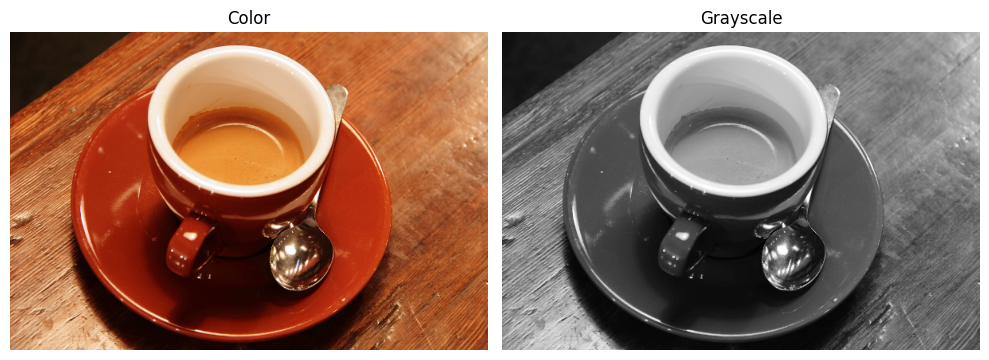

Color shape: (400, 600, 3)
Gray shape:  (400, 600)


In [10]:
gray = cv2.cvtColor(photo, cv2.COLOR_RGB2GRAY)   # cvtColor = convert color

show([photo, gray], ["Color", "Grayscale"])
print("Color shape:", photo.shape)
print("Gray shape: ", gray.shape)

### HSV
- **Hue:** which color (red, yellow, blue...). In 8-bit OpenCV images it goes from **0 to 179**
- **Saturation:** how strong the color is (0 to 255)
- **Value:** how bright it is (0 to 255)

HSV separates the *color* from the *brightness*, which makes selecting a color easier.

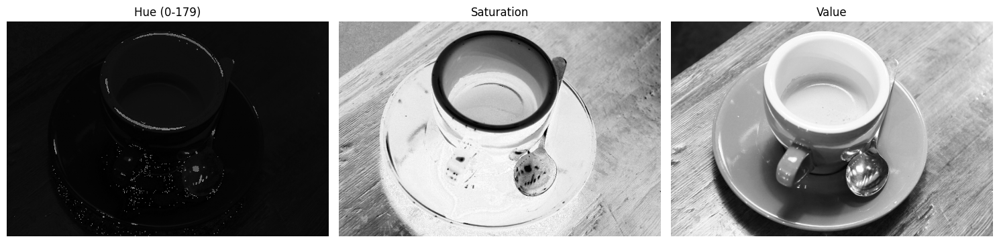

In [11]:
hsv = cv2.cvtColor(photo, cv2.COLOR_RGB2HSV)

show([hsv[:, :, 0], hsv[:, :, 1], hsv[:, :, 2]],
     ["Hue (0-179)", "Saturation", "Value"])

> **Why is the Hue picture almost black?** This photo is mostly orange, brown and red. Many of these hues are small numbers, and small numbers look dark. Hue is a **color code**, not a brightness.

### Mini project: select pixels by color
We will keep only **orange-brown** pixels using a **mask**.
A mask is a black-and-white image: **white = selected**, **black = not selected**.

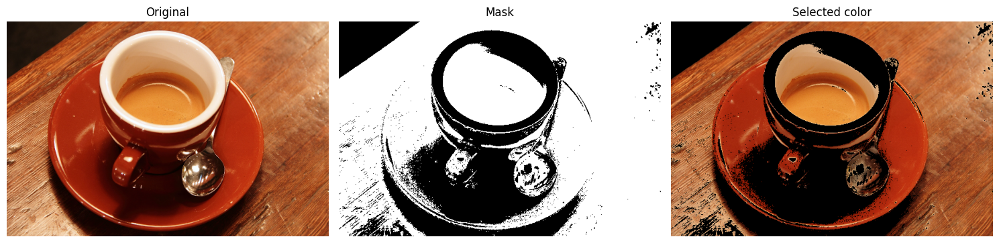

In [12]:
lower = np.array([5, 100, 50])     # lowest  [Hue, Saturation, Value]
upper = np.array([25, 255, 255])   # highest [Hue, Saturation, Value]

mask = cv2.inRange(hsv, lower, upper)
result = cv2.bitwise_and(photo, photo, mask=mask)   # keep only masked pixels

show([photo, mask, result], ["Original", "Mask", "Selected color"])

**What do you see?** Much of the wood and the coffee is selected, but large parts of the red saucer and cup are not. One reason: **red sits at both ends** of the hue scale (near 0 and near 179), and our range starts at 5. Saturation and Value limits also affect the result. Color selection often needs some trial and error.

> **Try it:** Change the hue limits (the first number in `lower` and `upper`) and see which areas are selected.

---
# Part 4: Image Filtering

A **filter** changes each pixel by looking at its **neighbors**.

Many filters use a **kernel**: a small grid of numbers (such as 3×3) that slides over the image. At every position:
1. Multiply each kernel number by the pixel under it
2. Add the results
3. That total becomes the new center pixel

This operation is called **convolution**. *(Technical note: OpenCV's `filter2D` does not flip the kernel, so strictly it computes correlation. For symmetric kernels, the result is the same.)*

### A calculation by hand

In [13]:
patch = np.array([[10, 10, 10],
                  [10, 100, 10],     # one bright pixel in the middle
                  [10, 10, 10]])

average_kernel = np.ones((3, 3)) / 9    # nine equal weights that add up to 1

new_value = np.sum(patch * average_kernel)
print("Old center value:", patch[1, 1])
print("New center value:", round(new_value))

Old center value: 100
New center value: 20


The bright spot dropped from **100 to 20** because it was averaged with its neighbors: (8 × 10 + 100) ÷ 9 = 20. **That is blurring!**

## 4.1 Blurring (smoothing)
Blurring reduces detail and noise.

| Method | How it works | Good for |
|---|---|---|
| **Average** | Plain average of neighbors | Simple smoothing |
| **Gaussian** | Weighted average, nearer pixels count more | Natural blur, preparing for edge detection |
| **Median** | Takes the middle value of neighbors | "Salt and pepper" noise (random white and black dots) |

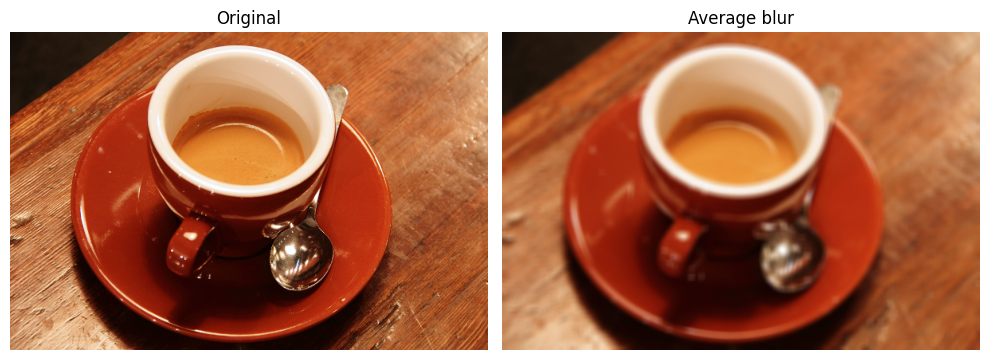

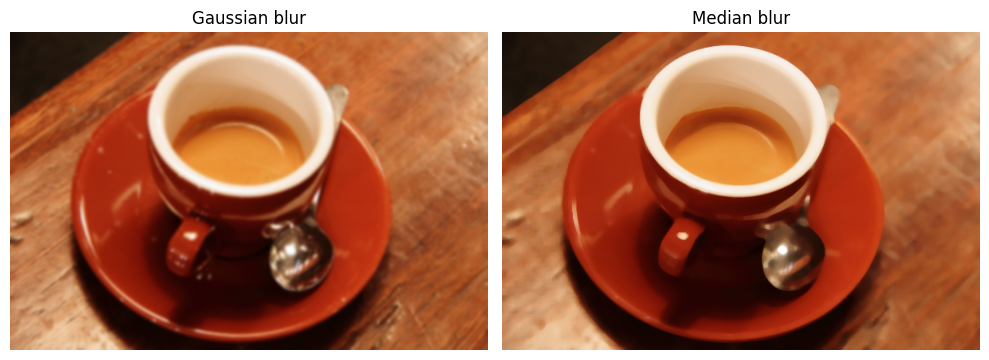

In [14]:
average  = cv2.blur(photo, (9, 9))                # (9, 9) = kernel size
gaussian = cv2.GaussianBlur(photo, (9, 9), 0)     # 0 = choose the spread automatically
median   = cv2.medianBlur(photo, 9)               # one number: 9 means 9 x 9

show([photo, average], ["Original", "Average blur"])
show([gaussian, median], ["Gaussian blur", "Median blur"])

> **Try it:** Replace `9` with `3`, then with `25`. A **bigger kernel gives more blur**.
> For `GaussianBlur` and `medianBlur`, use **odd** numbers (3, 5, 7...).

### Which blur removes noise best?
Let's add salt and pepper noise on purpose, then try to clean it.

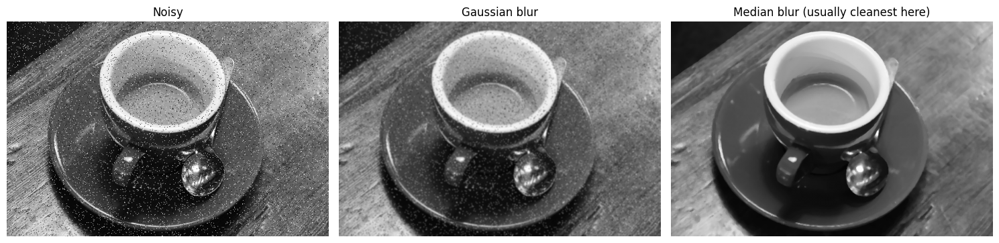

In [15]:
rng = np.random.default_rng(42)          # 42 makes the "random" noise repeatable
random_numbers = rng.random(gray.shape)  # one number between 0 and 1 per pixel

noisy = gray.copy()
noisy[random_numbers < 0.03] = 0         # about 3% of pixels become black
noisy[random_numbers > 0.97] = 255       # about 3% of pixels become white

show([noisy, cv2.GaussianBlur(noisy, (5, 5), 0), cv2.medianBlur(noisy, 5)],
     ["Noisy", "Gaussian blur", "Median blur (usually cleanest here)"])

## 4.2 Sharpening
Sharpening makes edges **stand out more** by increasing the difference between a pixel and its neighbors.

A common sharpening kernel:

|  |  |  |
|---|---|---|
| 0 | -1 | 0 |
| -1 | **5** | -1 |
| 0 | -1 | 0 |

It boosts the center and subtracts the neighbors. The numbers add up to **1**, so flat areas keep the same brightness.

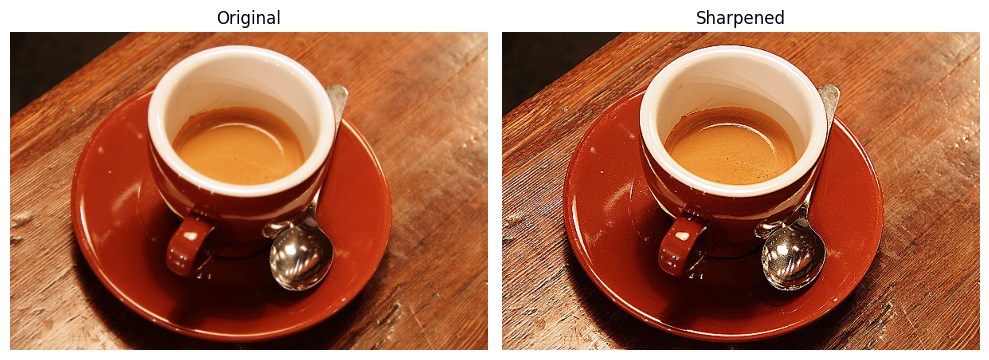

In [16]:
sharpen_kernel = np.array([[ 0, -1,  0],
                           [-1,  5, -1],
                           [ 0, -1,  0]])

# -1 means: keep the same data type as the input image
sharpened = cv2.filter2D(photo, -1, sharpen_kernel)

show([photo, sharpened], ["Original", "Sharpened"])

> Sharpening also makes **noise** stronger. It cannot truly restore detail that was never captured.

## 4.3 Edge detection
An **edge** is a place where brightness **changes suddenly**, often at the border of an object.
Edge detection is usually done on **grayscale** images.

### A) Sobel operator
Sobel measures how fast brightness changes in two directions:
- **Sobel X:** change from left to right → highlights **vertical** edges
- **Sobel Y:** change from top to bottom → highlights **horizontal** edges
- **Magnitude:** combines both: √(X² + Y²)

First, a simple shape so you can clearly see the difference:

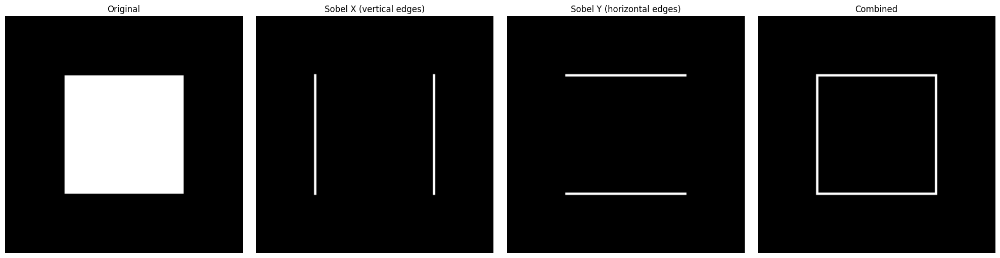

In [17]:
square = np.zeros((200, 200), dtype=np.uint8)   # black image
square[50:150, 50:150] = 255                     # white square

def sobel_edges(img):
    # CV_64F allows negative and large values, so no edge information is lost
    sx = cv2.Sobel(img, cv2.CV_64F, 1, 0, ksize=3)   # 1, 0 = x direction
    sy = cv2.Sobel(img, cv2.CV_64F, 0, 1, ksize=3)   # 0, 1 = y direction
    magnitude = cv2.magnitude(sx, sy)
    # convertScaleAbs: remove minus signs and limit values to 0-255
    return (cv2.convertScaleAbs(sx),
            cv2.convertScaleAbs(sy),
            cv2.convertScaleAbs(magnitude))

x, y, both = sobel_edges(square)
show([square, x, y, both],
     ["Original", "Sobel X (vertical edges)", "Sobel Y (horizontal edges)", "Combined"])

Now on a real photo (coins):

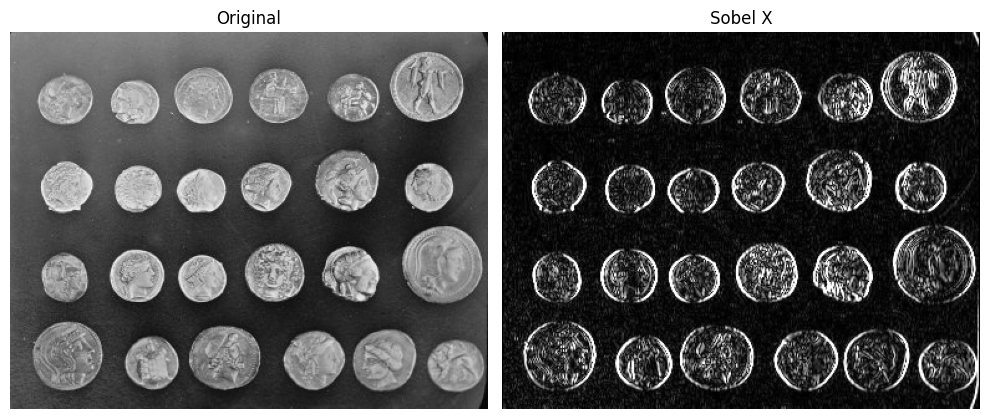

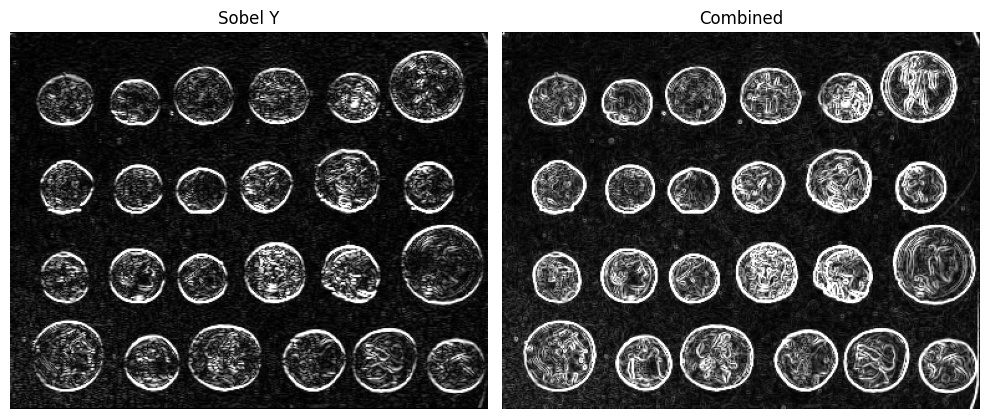

In [18]:
coins = data.coins()     # grayscale sample image

x, y, both = sobel_edges(coins)
show([coins, x], ["Original", "Sobel X"])
show([y, both], ["Sobel Y", "Combined"])

### B) Canny edge detector
Canny is a very popular method that usually gives **thin, clean edges**. Its steps:

1. **Smooth** the image to reduce noise
2. **Find gradients** (how strongly brightness changes, often using Sobel)
3. **Thin the edges** (non-maximum suppression: keep only the sharpest point across each edge)
4. **Double threshold:** sort pixels into strong, weak, or not an edge
5. **Hysteresis:** keep a weak edge only if it connects to a strong one

> OpenCV's `cv2.Canny` does steps 2 to 5. It does **not** apply the Gaussian blur for you, so we do step 1 ourselves.

**The two thresholds:**
- Above the **high** threshold → definitely an edge
- Below the **low** threshold → rejected
- In between → kept only if connected to a definite edge

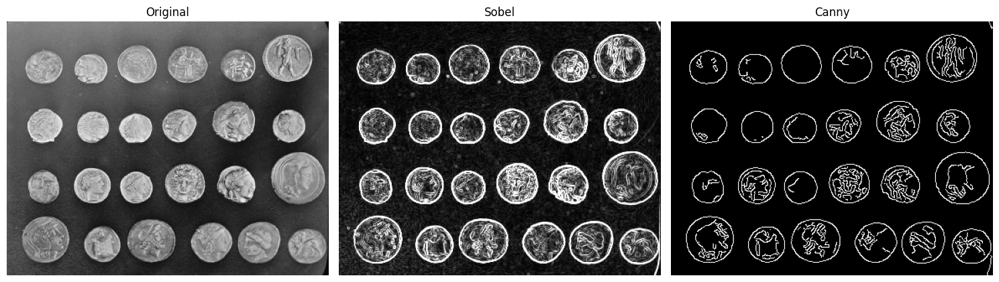

In [19]:
blurred = cv2.GaussianBlur(coins, (5, 5), 0)      # step 1

edges = cv2.Canny(blurred, 50, 150)               # low = 50, high = 150

show([coins, both, edges], ["Original", "Sobel", "Canny"])

### How do thresholds change the result?

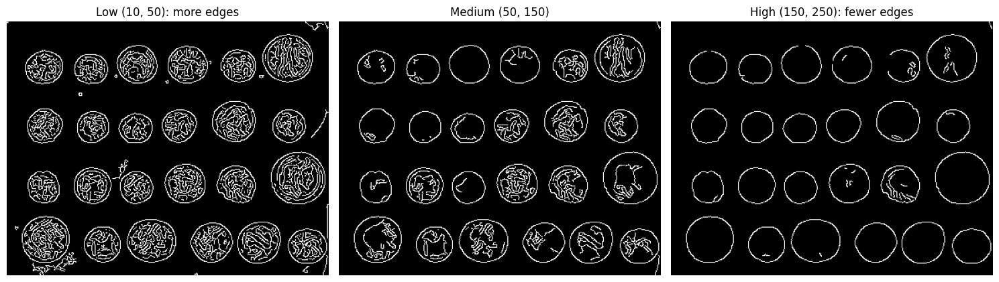

In [20]:
show([cv2.Canny(blurred, 10, 50),
      cv2.Canny(blurred, 50, 150),
      cv2.Canny(blurred, 150, 250)],
     ["Low (10, 50): more edges", "Medium (50, 150)", "High (150, 250): fewer edges"])

### Interactive Canny
Run this cell, then **drag the sliders**. (Sliders appear in Colab after you run the cell.)

In [21]:
from ipywidgets import interact, IntSlider

def try_canny(low, high):
    show([coins, cv2.Canny(blurred, low, high)], ["Original", f"Canny ({low}, {high})"])

_ = interact(try_canny,
             low=IntSlider(min=0, max=255, value=50, continuous_update=False),
             high=IntSlider(min=0, max=255, value=150, continuous_update=False))

interactive(children=(IntSlider(value=50, continuous_update=False, description='low', max=255), IntSlider(valu…

### Sobel vs Canny
| | Sobel | Canny |
|---|---|---|
| What it is | A gradient filter | A multi-step algorithm |
| Output | Shades of gray (edge strength) | Black and white (edge or not) |
| Edge thickness | Often thicker | Usually thin |
| Settings | Direction, kernel size | Two thresholds |
| Speed | Faster | Does more work |

---
# Part 5: The OpenCV Library

**OpenCV** (Open Source Computer Vision Library) is a free, widely used library for computer vision. It is written mainly in C++ and can be used from Python. We import it as `cv2`.

### Two things every beginner must know
1. OpenCV reads color images in **BGR** order, but Matplotlib expects **RGB**.
2. `cv2.imshow()` opens a desktop window, which **does not work in Colab**. Use our `show()` function (or Colab's `cv2_imshow`).

## 5.1 Saving and reading images

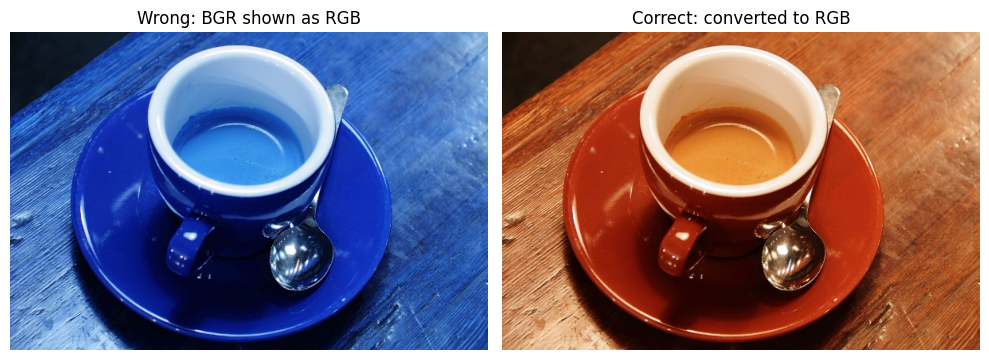

In [22]:
# Our photo is RGB. OpenCV expects BGR when saving, so convert first.
cv2.imwrite("coffee.jpg", cv2.cvtColor(photo, cv2.COLOR_RGB2BGR))

loaded_bgr = cv2.imread("coffee.jpg")                       # read (comes back as BGR)
loaded_rgb = cv2.cvtColor(loaded_bgr, cv2.COLOR_BGR2RGB)    # convert for display

show([loaded_bgr, loaded_rgb], ["Wrong: BGR shown as RGB", "Correct: converted to RGB"])

> If your colors look strange (blue where it should be orange), check BGR and RGB first!
> If the file name or path is wrong, `cv2.imread` returns `None` instead of showing an error message right away.

## 5.2 Resize, rotate, flip

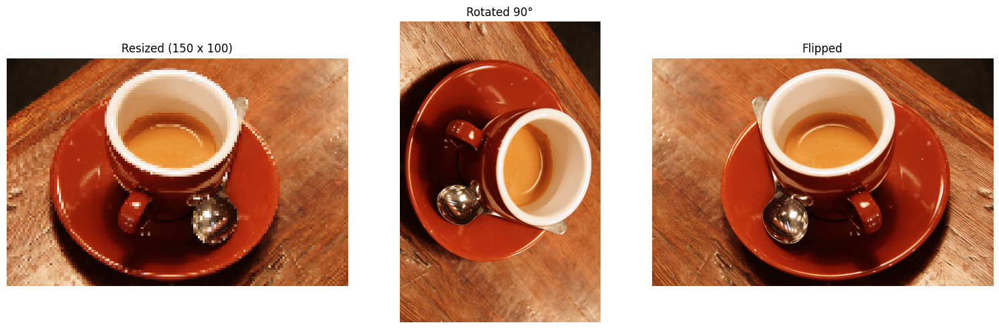

Original: (400, 600, 3) | Resized: (100, 150, 3)


In [23]:
small   = cv2.resize(photo, (150, 100))               # (width, height)
rotated = cv2.rotate(photo, cv2.ROTATE_90_CLOCKWISE)
flipped = cv2.flip(photo, 1)                          # 1 = left-right, 0 = upside down

show([small, rotated, flipped], ["Resized (150 x 100)", "Rotated 90°", "Flipped"])
print("Original:", photo.shape, "| Resized:", small.shape)

*(The small image looks blocky because it is stretched to the same display size.)*

## 5.3 Brightness and contrast
**new pixel = alpha × old pixel + beta**
- `alpha` controls **contrast** (above 1 = more contrast)
- `beta` controls **brightness** (above 0 = brighter)

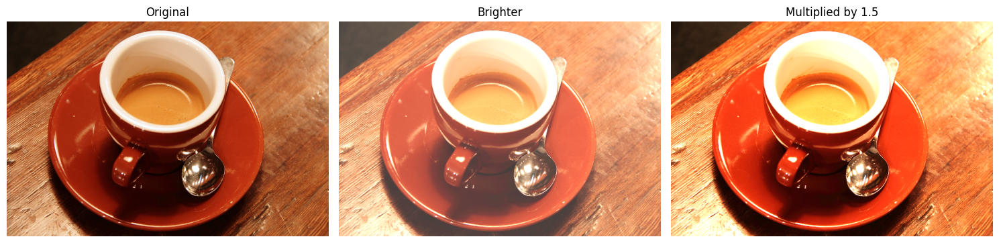

In [24]:
brighter = cv2.convertScaleAbs(photo, alpha=1.0, beta=60)
contrast = cv2.convertScaleAbs(photo, alpha=1.5, beta=0)    # also looks brighter

show([photo, brighter, contrast], ["Original", "Brighter", "Multiplied by 1.5"])

## 5.4 Drawing shapes and text
Useful for marking things the computer finds.

Drawing functions use **(x, y)** = (column, row). This is the **opposite** order of `image[row, column]`.

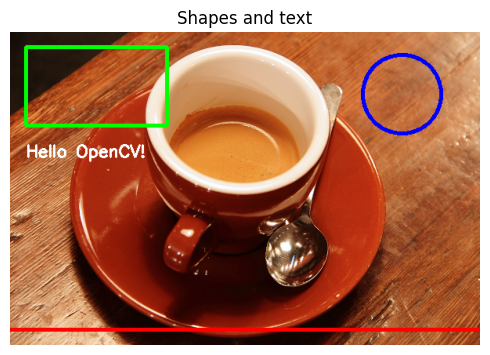

In [25]:
canvas = photo.copy()

# Our image is RGB, so (0, 255, 0) is green. Thickness 4 pixels.
cv2.rectangle(canvas, (20, 20), (200, 120), (0, 255, 0), 4)      # two opposite corners
cv2.circle(canvas, (500, 80), 50, (0, 0, 255), 4)                # center, radius
cv2.line(canvas, (0, 380), (599, 380), (255, 0, 0), 4)           # start, end
cv2.putText(canvas, "Hello OpenCV!", (20, 160),
            cv2.FONT_HERSHEY_SIMPLEX, 0.7, (255, 255, 255), 2)

show([canvas], ["Shapes and text"])

## 5.5 Thresholding
Thresholding turns a grayscale image into **pure black and white**.
**Otsu's method** picks the threshold value automatically.

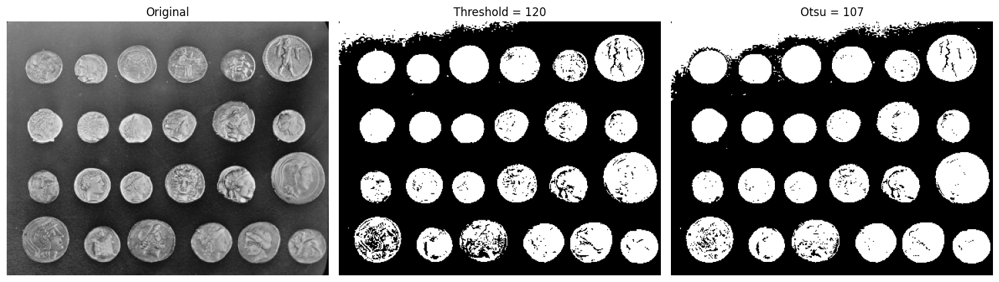

In [26]:
_, manual = cv2.threshold(coins, 120, 255, cv2.THRESH_BINARY)

value, otsu = cv2.threshold(coins, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)

show([coins, manual, otsu], ["Original", "Threshold = 120", f"Otsu = {int(value)}"])

**Notice the white patch near the top of both results.** The lighting in this photo is uneven, so part of the background is as bright as some coins. One threshold for the whole image struggles with this. `cv2.adaptiveThreshold`, which uses a different threshold for each area, is one option to explore.

---
# Part 6: Applications in Action

## Application 1: Find and outline shapes
**Contours** are the outlines of shapes. We will make a clean image, then find, count and name its shapes.

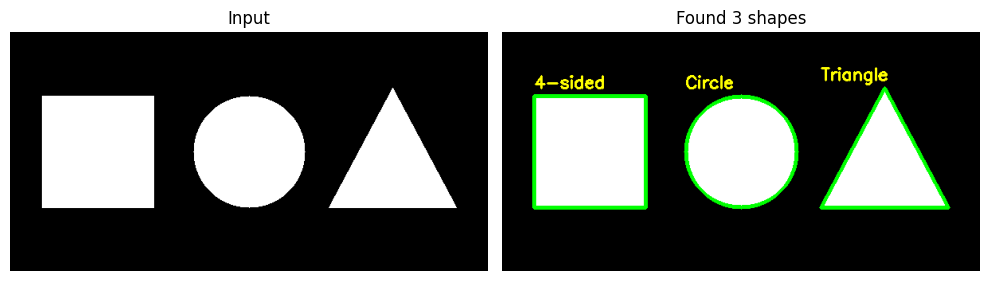

In [27]:
shapes = np.zeros((300, 600), dtype=np.uint8)                      # black background
cv2.rectangle(shapes, (40, 80), (180, 220), 255, -1)               # -1 = filled
cv2.circle(shapes, (300, 150), 70, 255, -1)
triangle = np.array([[480, 70], [400, 220], [560, 220]])
cv2.fillPoly(shapes, [triangle], 255)

contours, _ = cv2.findContours(shapes, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)

output = cv2.cvtColor(shapes, cv2.COLOR_GRAY2RGB)   # color copy, so we can draw in color

for c in contours:
    # Simplify the outline, then count its corners
    corners = cv2.approxPolyDP(c, 0.03 * cv2.arcLength(c, True), True)

    if len(corners) == 3:
        name = "Triangle"
    elif len(corners) == 4:
        name = "4-sided"
    else:
        name = "Circle"      # good enough for this simple example only

    x, y, w, h = cv2.boundingRect(c)     # box around the shape
    cv2.drawContours(output, [c], -1, (0, 255, 0), 4)
    cv2.putText(output, name, (x, y - 10), cv2.FONT_HERSHEY_SIMPLEX, 0.7, (255, 255, 0), 2)

show([shapes, output], ["Input", f"Found {len(contours)} shapes"])

## Application 2: Face detection
OpenCV includes a ready-trained **Haar Cascade** face detector. It is an older, fast method that works best on **clear, front-facing faces**.

This is face **detection** (*where* is a face?), not face **recognition** (*who* is it?).

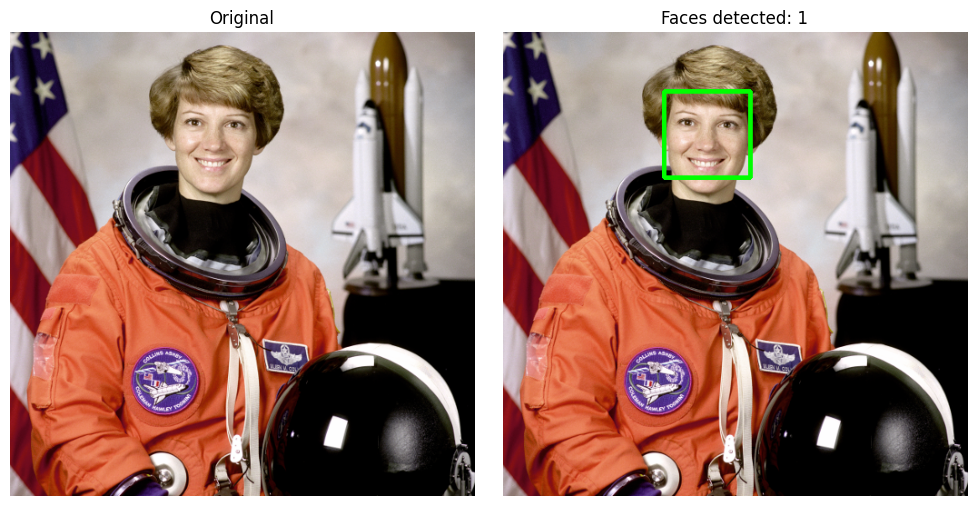

In [28]:
person = data.astronaut()     # sample color photo
person_gray = cv2.cvtColor(person, cv2.COLOR_RGB2GRAY)

detector = cv2.CascadeClassifier(cv2.data.haarcascades + "haarcascade_frontalface_default.xml")

faces = detector.detectMultiScale(person_gray,
                                  scaleFactor=1.1,    # search at several face sizes
                                  minNeighbors=5,     # higher = stricter
                                  minSize=(60, 60))   # ignore tiny detections

found = person.copy()
for (x, y, w, h) in faces:
    cv2.rectangle(found, (x, y), (x + w, y + h), (0, 255, 0), 4)

show([person, found], ["Original", f"Faces detected: {len(faces)}"])

> Detectors can **miss** faces or mark **false** ones. Changing `scaleFactor`, `minNeighbors` and `minSize` changes the result.

## Application 3: Pencil sketch effect
We combine what you learned: **grayscale → invert → blur → divide**.

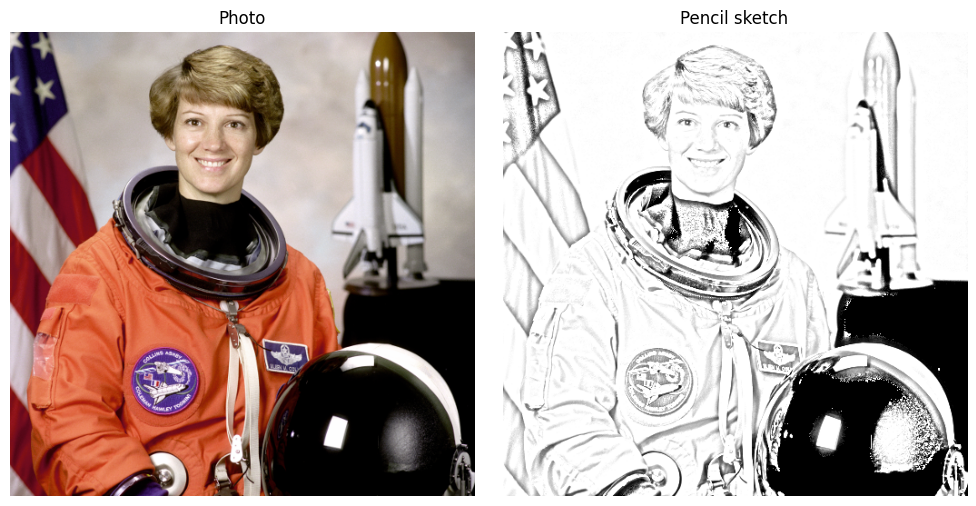

In [29]:
person_blur = cv2.GaussianBlur(255 - person_gray, (21, 21), 0)     # 255 - image = invert
sketch = cv2.divide(person_gray, 255 - person_blur, scale=256)

show([person, sketch], ["Photo", "Pencil sketch"])

---
# Part 7: Use your own image
1. In the cell below, change `USE_MY_IMAGE = False` to `USE_MY_IMAGE = True`
2. Run the cell and click **Choose Files**
3. Pick a `.jpg` or `.png` image

If you leave it as `False`, the sample photo is used. Uploading works only in Google Colab.

> Your file is uploaded to your Colab session. Avoid private photos, and get permission before using photos of other people.

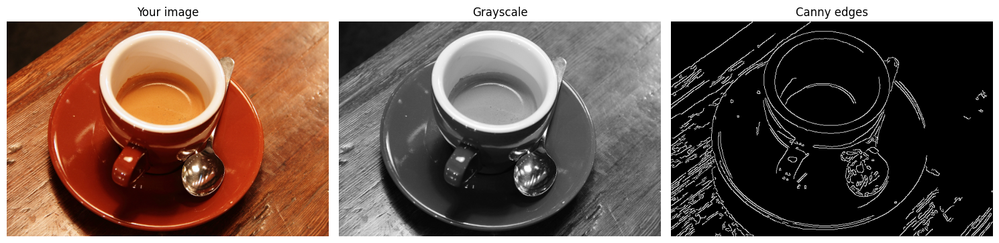

In [30]:
USE_MY_IMAGE = False     # change to True to upload your own picture

if USE_MY_IMAGE:
    from google.colab import files
    uploaded = files.upload()
    filename = next(iter(uploaded))                         # name of the first file
    file_bytes = np.frombuffer(uploaded[filename], np.uint8)
    my_bgr = cv2.imdecode(file_bytes, cv2.IMREAD_COLOR)
    if my_bgr is None:
        raise ValueError("Could not read this file. Please use a JPG or PNG image.")
    my_image = cv2.cvtColor(my_bgr, cv2.COLOR_BGR2RGB)
else:
    my_image = data.coffee()

my_gray = cv2.cvtColor(my_image, cv2.COLOR_RGB2GRAY)
my_blur = cv2.GaussianBlur(my_gray, (5, 5), 0)

show([my_image, my_gray, cv2.Canny(my_blur, 50, 150)], ["Your image", "Grayscale", "Canny edges"])

> Large photos have many more pixels, so the same blur kernel looks weaker on them.

---
# Part 8: Practice time

Try each exercise yourself **before** opening the solution. Use `photo` as your input.

1. Convert `photo` to grayscale and print its shape.
2. Crop the top-left 200 × 200 pixels.
3. Apply a Gaussian blur with a 15 × 15 kernel.
4. Find edges with Canny using thresholds 100 and 200.
5. Flip the image upside down and draw a red rectangle on it.

In [31]:
# Exercise 1: write your code here

In [32]:
# Exercise 2: write your code here

In [33]:
# Exercise 3: write your code here

In [34]:
# Exercise 4: write your code here

In [35]:
# Exercise 5: write your code here

<details>
<summary><b>Click to see the solutions</b></summary>

```python
# 1
g = cv2.cvtColor(photo, cv2.COLOR_RGB2GRAY)
print(g.shape)

# 2
show([photo[0:200, 0:200]], ["Top-left crop"])

# 3
show([cv2.GaussianBlur(photo, (15, 15), 0)], ["Blurred"])

# 4  (run exercise 1 first; blur before Canny to reduce noise)
smooth = cv2.GaussianBlur(g, (5, 5), 0)
show([cv2.Canny(smooth, 100, 200)], ["Edges"])

# 5
ans = cv2.flip(photo, 0)
cv2.rectangle(ans, (50, 50), (250, 200), (255, 0, 0), 4)
show([ans], ["Answer"])
```
</details>

---
## Quick quiz
1. What is a pixel?
2. What is the shape of a color image that is 800 wide and 600 tall?
3. In what order does OpenCV store color channels?
4. Which blur is a good choice for salt and pepper noise?
5. Which edges does Sobel X highlight?
6. Why do we blur before Canny?

<details>
<summary><b>Click to see the answers</b></summary>

1. The smallest element in the grid that makes up a digital image.
2. `(600, 800, 3)`: height, width, channels.
3. BGR (Blue, Green, Red).
4. Median blur.
5. Vertical edges (brightness changing from left to right).
6. To reduce noise, which could otherwise be detected as false edges.
</details>

---
# Summary and cheat sheet

| I want to... | Code |
|---|---|
| Read an image | `cv2.imread("file.jpg")` |
| Save an image | `cv2.imwrite("out.jpg", img)` |
| BGR → RGB | `cv2.cvtColor(img, cv2.COLOR_BGR2RGB)` |
| RGB → Gray | `cv2.cvtColor(img, cv2.COLOR_RGB2GRAY)` |
| RGB → HSV | `cv2.cvtColor(img, cv2.COLOR_RGB2HSV)` |
| Resize | `cv2.resize(img, (width, height))` |
| Average blur | `cv2.blur(img, (5, 5))` |
| Gaussian blur | `cv2.GaussianBlur(img, (5, 5), 0)` |
| Median blur | `cv2.medianBlur(img, 5)` |
| Custom filter (e.g. sharpen) | `cv2.filter2D(img, -1, kernel)` |
| Sobel | `cv2.Sobel(img, cv2.CV_64F, 1, 0, ksize=3)` |
| Canny | `cv2.Canny(img, 50, 150)` |
| Threshold | `cv2.threshold(img, 120, 255, cv2.THRESH_BINARY)` |
| Find outlines | `cv2.findContours(...)` |

### Key takeaways
- An image is **an array of numbers**
- **Color models** (RGB, Grayscale, HSV...) describe color in different ways
- **Filters** change pixels using their neighbors
- **Edges** are sudden brightness changes
- **OpenCV** gives you ready-made tools for all of this

**Congratulations, you completed Module 5!**